In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

genres = ["Drama", "Comedy", "Action", "Thriller", "Documentary", "Romance"]
plans = ["Basic", "Standard", "Premium"]

data = pd.DataFrame({
    "User_ID": [f"U{i:04d}" for i in range(1, n + 1)],

    "Viewing_History": np.random.randint(5, 101, n),

    "Session_Duration": np.random.randint(10, 181, n),

    "Content_Genre": np.random.choice(genres, n),

    "Subscription_Plan": np.random.choice(
        plans,
        n,
        p=[0.4, 0.35, 0.25]
    ),

    "Inactivity_Period": np.random.randint(0, 31, n)
})

data.head()

,User_ID,Viewing_History,Session_Duration,Content_Genre,Subscription_Plan,Inactivity_Period
0,U0001,56,143,Drama,Basic,3
1,U0002,97,127,Documentary,Premium,0
2,U0003,19,122,Thriller,Standard,18
3,U0004,76,103,Comedy,Premium,25
4,U0005,65,71,Documentary,Standard,24


**Create Retention Status**

In [2]:
score = (
    data["Session_Duration"] * 0.4
    + data["Viewing_History"] * 0.3
    - data["Inactivity_Period"] * 2
)

data["Retention_Status"] = np.where(
    score > score.median(),
    "Retained",
    "Churned"
)

data.head()

,User_ID,Viewing_History,Session_Duration,Content_Genre,Subscription_Plan,Inactivity_Period,Retention_Status
0,U0001,56,143,Drama,Basic,3,Retained
1,U0002,97,127,Documentary,Premium,0,Retained
2,U0003,19,122,Thriller,Standard,18,Churned
3,U0004,76,103,Comedy,Premium,25,Churned
4,U0005,65,71,Documentary,Standard,24,Churned


In [3]:
data.to_csv("ott_user_behavior.csv", index=False)

print("Dataset created successfully!")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

Dataset created successfully!
Rows: 1000
Columns: 7


In [4]:
data.shape

(1000, 7)

In [5]:
data.describe()

,Viewing_History,Session_Duration,Inactivity_Period
count,1000.000000,1000.000000,1000.000000
mean,52.005000,93.878000,15.640000
std,28.351133,50.234437,8.803516
min,5.000000,10.000000,0.000000
25%,27.000000,49.000000,8.000000
50%,53.000000,93.000000,16.000000
75%,76.000000,138.250000,23.000000
max,100.000000,180.000000,30.000000


**What kind of users do we have?**

In [6]:
print("Genres:")
print(data["Content_Genre"].value_counts())

print("\nSubscription Plans:")
print(data["Subscription_Plan"].value_counts())

print("\nRetention Status:")
print(data["Retention_Status"].value_counts())

Genres:
Content_Genre
Documentary    178
Thriller       178
Comedy         177
Romance        169
Drama          161
Action         137
Name: count, dtype: int64

Subscription Plans:
Subscription_Plan
Basic       385
Standard    357
Premium     258
Name: count, dtype: int64

Retention Status:
Retention_Status
Churned     501
Retained    499
Name: count, dtype: int64


In [7]:
data.isnull().sum()

,0
User_ID,0
Viewing_History,0
Session_Duration,0
Content_Genre,0
Subscription_Plan,0
Inactivity_Period,0
Retention_Status,0


In [8]:
data["User_ID"].duplicated().sum()

np.int64(0)

In [9]:
print("Negative session durations:",
      (data["Session_Duration"] < 0).sum())

print("Negative inactivity periods:",
      (data["Inactivity_Period"] < 0).sum())

print("Negative viewing history:",
      (data["Viewing_History"] < 0).sum())

Negative session durations: 0
Negative inactivity periods: 0
Negative viewing history: 0


**How long does the average user watch?**

In [10]:
average_watch_time = data["Session_Duration"].mean()

print("Average Session Duration:",
      round(average_watch_time, 2), "minutes")

Average Session Duration: 93.88 minutes


**Do different subscription plans have different viewing behaviour?**

In [11]:
data.groupby("Subscription_Plan")["Session_Duration"].mean()

,Session_Duration
Subscription_Plan,
Basic,94.503896
Premium,94.019380
Standard,93.100840


**Average watch time by retention status**

In [12]:
data.groupby("Retention_Status")["Session_Duration"].mean()

,Session_Duration
Retention_Status,
Churned,61.323353
Retained,126.563126


**Do churned users have longer inactivity periods?**

In [13]:
data.groupby("Retention_Status")["Inactivity_Period"].mean()

,Inactivity_Period
Retention_Status,
Churned,19.928144
Retained,11.334669


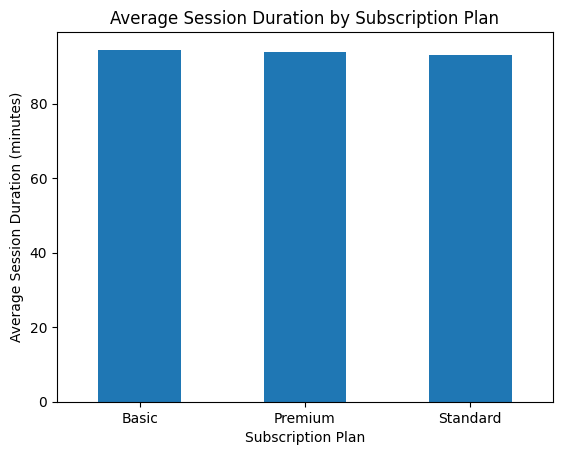

In [14]:
import matplotlib.pyplot as plt

avg_watch = data.groupby("Subscription_Plan")["Session_Duration"].mean()

avg_watch.plot(kind="bar")

plt.title("Average Session Duration by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Average Session Duration (minutes)")
plt.xticks(rotation=0)
plt.show()

**Retained vs Churned users**

In [15]:
retention_counts = data["Retention_Status"].value_counts()

print(retention_counts)

Retention_Status
Churned     501
Retained    499
Name: count, dtype: int64


In [16]:
retention_percentage = data["Retention_Status"].value_counts(normalize=True) * 100

print(retention_percentage.round(2))

Retention_Status
Churned     50.1
Retained    49.9
Name: proportion, dtype: float64


**Do retained and churned users behave differently in terms of watch time?**

In [17]:
data.groupby("Retention_Status")["Session_Duration"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Retention_Status,,,,,
Churned,501,61.32,54.0,10,171
Retained,499,126.56,132.0,12,180


**Are churned users inactive for longer periods?**

Compare inactivity

In [18]:
data.groupby("Retention_Status")["Inactivity_Period"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Retention_Status,,,,,
Churned,501,19.93,21.0,0,30
Retained,499,11.33,10.0,0,30


**Compare viewing history**

In [19]:
data.groupby("Retention_Status")["Viewing_History"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Retention_Status,,,,,
Churned,501,44.79,40.0,5,100
Retained,499,59.25,62.0,5,100


**Do retained users spend more time watching in each session than churned users?**

In [20]:
data.groupby("Retention_Status")["Session_Duration"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Retention_Status,,,,,
Churned,501,61.32,54.0,10,171
Retained,499,126.56,132.0,12,180


**Content Diversity**

In [25]:
np.random.seed(42)

data["Content_Diversity"] = (
    1
    + (data["Viewing_History"] / 20).astype(int)
    + np.random.choice([-1, 0, 0, 0, 1], size=len(data))
)

# Keep diversity between 1 and 6
data["Content_Diversity"] = data["Content_Diversity"].clip(1, 6)

data[[
    "User_ID",
    "Viewing_History",
    "Content_Diversity",
    "Session_Duration",
    "Retention_Status"
]].head(10)

,User_ID,Viewing_History,Content_Diversity,Session_Duration,Retention_Status
0,U0001,56,3,143,Retained
1,U0002,97,6,127,Retained
2,U0003,19,1,122,Churned
3,U0004,76,5,103,Churned
4,U0005,65,5,71,Churned
5,U0006,25,2,88,Retained
6,U0007,87,5,145,Retained
7,U0008,91,5,35,Churned
8,U0009,79,4,53,Churned
9,U0010,79,5,142,Retained


**Do users with different levels of content diversity have different average session durations?**

In [26]:
diversity_analysis = data.groupby(
    "Content_Diversity"
)["Session_Duration"].agg(
    ["count", "mean", "median"]
).round(2)

diversity_analysis

,count,mean,median
Content_Diversity,,,
1,184,91.81,90.0
2,191,89.48,85.0
3,190,96.17,95.0
4,224,96.26,96.0
5,164,94.20,96.0
6,47,98.11,107.0


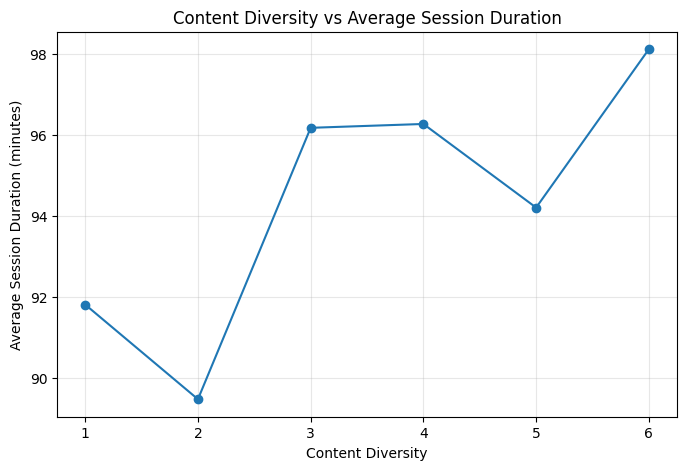

In [27]:
import matplotlib.pyplot as plt

avg_duration_by_diversity = data.groupby(
    "Content_Diversity"
)["Session_Duration"].mean()

plt.figure(figsize=(8, 5))

plt.plot(
    avg_duration_by_diversity.index,
    avg_duration_by_diversity.values,
    marker="o"
)

plt.title("Content Diversity vs Average Session Duration")
plt.xlabel("Content Diversity")
plt.ylabel("Average Session Duration (minutes)")
plt.xticks(range(1, 7))
plt.grid(True, alpha=0.3)

plt.show()

**Do retained and churned users differ in content diversity?**

In [28]:
diversity_retention = data.groupby(
    "Retention_Status"
)["Content_Diversity"].mean().round(2)

print(diversity_retention)

Retention_Status
Churned     2.81
Retained    3.46
Name: Content_Diversity, dtype: float64


In [30]:
correlation = data["Content_Diversity"].corr(
    data["Session_Duration"]
)

print(
    "Correlation between Content Diversity and Session Duration:",
    round(correlation, 3)
)

Correlation between Content Diversity and Session Duration: 0.038


**"Identify different viewing behaviour patterns."**

In [31]:
data[
    [
        "Viewing_History",
        "Session_Duration",
        "Inactivity_Period"
    ]
].describe().round(2)

,Viewing_History,Session_Duration,Inactivity_Period
count,1000.00,1000.00,1000.00
mean,52.00,93.88,15.64
std,28.35,50.23,8.80
min,5.00,10.00,0.00
25%,27.00,49.00,8.00
50%,53.00,93.00,16.00
75%,76.00,138.25,23.00
max,100.00,180.00,30.00


**Create an Engagement Score**

In [32]:
data["Engagement_Score"] = (
    data["Viewing_History"] * 0.4
    + data["Session_Duration"] * 0.4
    - data["Inactivity_Period"] * 0.2
)

data[[
    "User_ID",
    "Viewing_History",
    "Session_Duration",
    "Inactivity_Period",
    "Engagement_Score"
]].head(10)

,User_ID,Viewing_History,Session_Duration,Inactivity_Period,Engagement_Score
0,U0001,56,143,3,79.0
1,U0002,97,127,0,89.6
2,U0003,19,122,18,52.8
3,U0004,76,103,25,66.6
4,U0005,65,71,24,49.6
5,U0006,25,88,9,43.4
6,U0007,87,145,20,88.8
7,U0008,91,35,14,47.6
8,U0009,79,53,26,47.6
9,U0010,79,142,21,84.2


**Create four behavioural segments**

In [34]:
q25 = data["Engagement_Score"].quantile(0.25)
q50 = data["Engagement_Score"].quantile(0.50)
q75 = data["Engagement_Score"].quantile(0.75)

def assign_segment(score):
    if score >= q75:
        return "Highly Engaged"
    elif score >= q50:
        return "Moderately Engaged"
    elif score >= q25:
        return "At Risk"
    else:
        return "Inactive"

data["Behaviour_Segment"] = data["Engagement_Score"].apply(
    assign_segment
)

In [35]:
data["Behaviour_Segment"].value_counts()

,count
Behaviour_Segment,
Highly Engaged,252
Moderately Engaged,251
Inactive,250
At Risk,247


In [36]:
segment_analysis = data.groupby(
    "Behaviour_Segment"
).agg(
    Users=("User_ID", "count"),
    Avg_Viewing_History=("Viewing_History", "mean"),
    Avg_Session_Duration=("Session_Duration", "mean"),
    Avg_Inactivity=("Inactivity_Period", "mean"),
    Avg_Content_Diversity=("Content_Diversity", "mean")
).round(2)

segment_analysis

,Users,Avg_Viewing_History,Avg_Session_Duration,Avg_Inactivity,Avg_Content_Diversity
Behaviour_Segment,,,,,
At Risk,247,51.86,71.65,16.14,3.18
Highly Engaged,252,70.71,151.00,14.36,3.99
Inactive,250,32.04,37.42,17.00,2.20
Moderately Engaged,251,53.24,114.63,15.09,3.16


**Early signs of declining engagement**

"Identify early signs of declining engagement."

In [37]:
risk_analysis = data.groupby(
    "Behaviour_Segment"
).agg(
    Avg_Session_Duration=("Session_Duration", "mean"),
    Avg_Inactivity=("Inactivity_Period", "mean"),
    Avg_Viewing_History=("Viewing_History", "mean"),
    Avg_Content_Diversity=("Content_Diversity", "mean")
).round(2)

risk_analysis

,Avg_Session_Duration,Avg_Inactivity,Avg_Viewing_History,Avg_Content_Diversity
Behaviour_Segment,,,,
At Risk,71.65,16.14,51.86,3.18
Highly Engaged,151.00,14.36,70.71,3.99
Inactive,37.42,17.00,32.04,2.20
Moderately Engaged,114.63,15.09,53.24,3.16


**Behaviour Segment vs Average Session Duration**

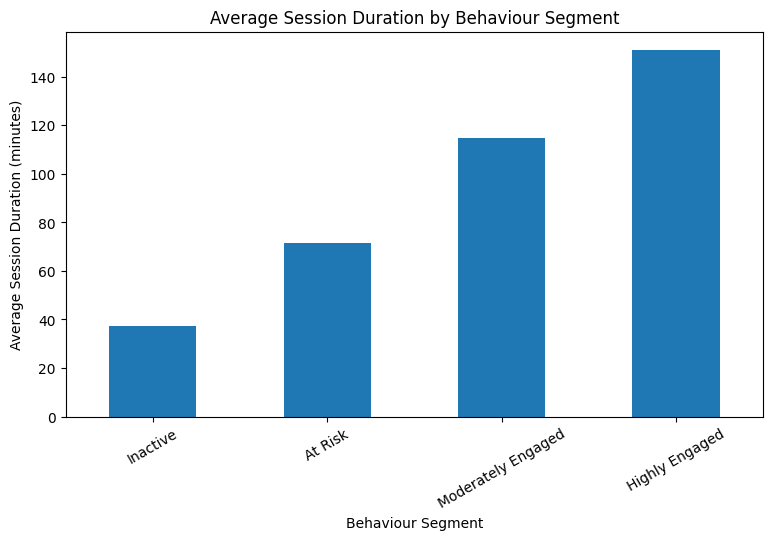

In [38]:
segment_session = data.groupby(
    "Behaviour_Segment"
)["Session_Duration"].mean().sort_values()

plt.figure(figsize=(9, 5))

segment_session.plot(kind="bar")

plt.title("Average Session Duration by Behaviour Segment")
plt.xlabel("Behaviour Segment")
plt.ylabel("Average Session Duration (minutes)")
plt.xticks(rotation=30)

plt.show()

**Retention by Subscription Plan**

Compare different subscription plans.

In [39]:
retention_by_plan = pd.crosstab(
    data["Subscription_Plan"],
    data["Retention_Status"],
    normalize="index"
) * 100

retention_by_plan.round(2)

Retention_Status,Churned,Retained
Subscription_Plan,,
Basic,49.87,50.13
Premium,49.61,50.39
Standard,50.70,49.30


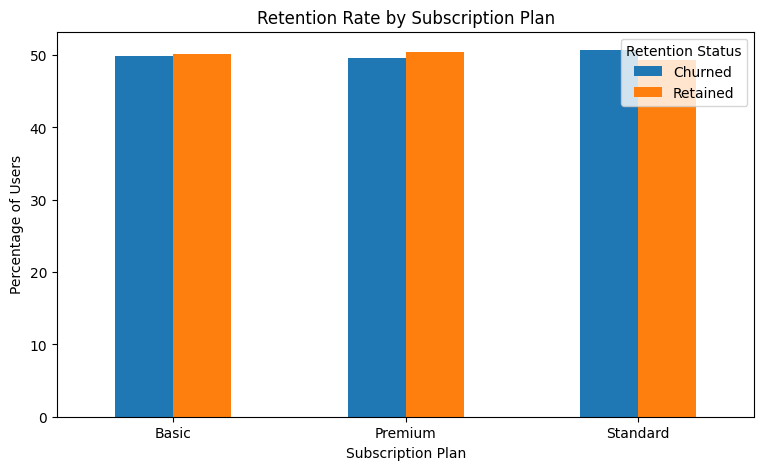

In [40]:
retention_by_plan.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Retention Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Percentage of Users")
plt.xticks(rotation=0)
plt.legend(title="Retention Status")

plt.show()

**Random Forest**

Build and evaluate a Random Forest model for the prediction target.

In [41]:
features = [
    "Viewing_History",
    "Session_Duration",
    "Content_Diversity",
    "Inactivity_Period",
    "Subscription_Plan"
]

X = data[features]
y = data["Retention_Status"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Viewing_History  Session_Duration  Content_Diversity  Inactivity_Period  \
0               56               143                  3                  3   
1               97               127                  6                  0   
2               19               122                  1                 18   
3               76               103                  5                 25   
4               65                71                  5                 24   

  Subscription_Plan  
0             Basic  
1           Premium  
2          Standard  
3           Premium  
4          Standard  

Target:
0    Retained
1    Retained
2     Churned
3     Churned
4     Churned
Name: Retention_Status, dtype: object


Encode Subscription Plan

In [42]:
X_encoded = pd.get_dummies(
    X,
    columns=["Subscription_Plan"],
    drop_first=False
)

print("Encoded features:")
print(X_encoded.head())

print("\nFeature columns:")
print(X_encoded.columns.tolist())

Encoded features:
   Viewing_History  Session_Duration  Content_Diversity  Inactivity_Period  \
0               56               143                  3                  3   
1               97               127                  6                  0   
2               19               122                  1                 18   
3               76               103                  5                 25   
4               65                71                  5                 24   

   Subscription_Plan_Basic  Subscription_Plan_Premium  \
0                     True                      False   
1                    False                       True   
2                    False                      False   
3                    False                       True   
4                    False                      False   

   Subscription_Plan_Standard  
0                       False  
1                       False  
2                        True  
3                       False  
4         

**Train/Test Split**

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Predictions

In [45]:
y_pred = rf_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['Retained' 'Churned' 'Churned' 'Churned' 'Retained' 'Retained' 'Retained'
 'Retained' 'Churned' 'Churned' 'Retained' 'Retained' 'Retained' 'Churned'
 'Churned' 'Churned' 'Retained' 'Retained' 'Retained' 'Churned']


Accuracy

In [46]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:",
      round(accuracy * 100, 2), "%")

Random Forest Accuracy: 95.0 %


In [47]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred
    )
)

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

     Churned       0.99      0.91      0.95       100
    Retained       0.92      0.99      0.95       100

    accuracy                           0.95       200
   macro avg       0.95      0.95      0.95       200
weighted avg       0.95      0.95      0.95       200



**Confusion Matrix**

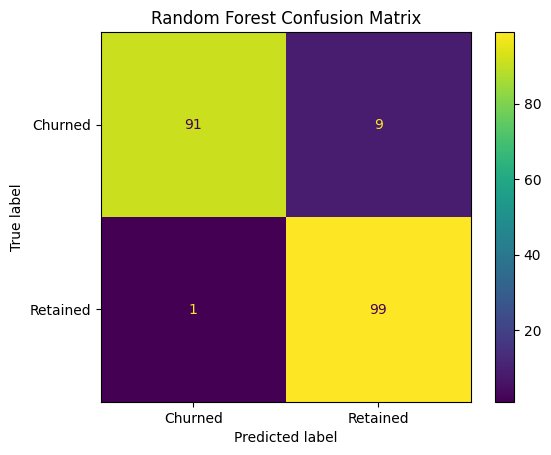

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

**Feature Importance**

In [49]:
feature_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,Session_Duration,0.522590
3,Inactivity_Period,0.292616
0,Viewing_History,0.124320
2,Content_Diversity,0.041928
6,Subscription_Plan_Standard,0.006461
4,Subscription_Plan_Basic,0.006112
5,Subscription_Plan_Premium,0.005972


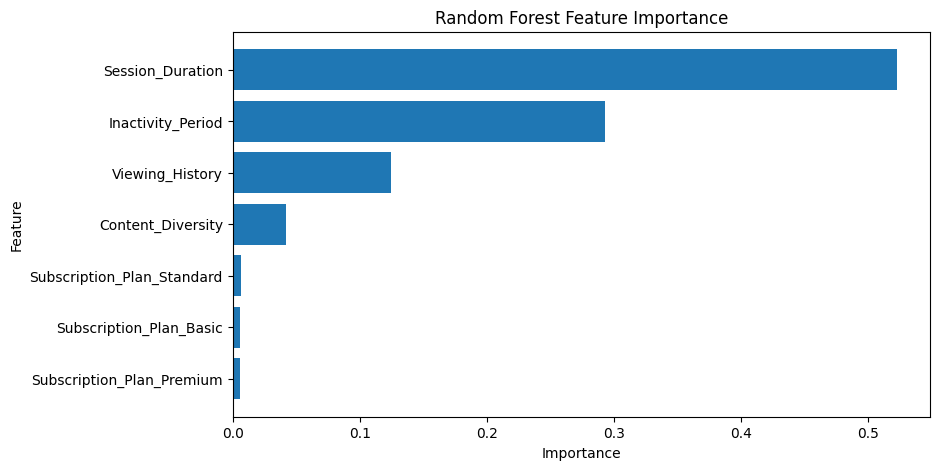

In [50]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

**Key insights**

**Insight 1 — Session duration is the strongest retention signal**

The Random Forest assigned approximately 52% feature importance to Session_Duration, making it the most influential feature in the model.

**Insight 2 — Inactivity is an important warning signal**

Inactivity_Period was the second most important feature at approximately 29% importance.

Our behavioural analysis also shows:

Highly Engaged → 14.36 days inactivity
At Risk → 16.14 days
Inactive → 17.00 days

This supports using prolonged inactivity as an engagement-risk indicator.

**Insight 3 — Highly engaged users watch substantially longer**

The Highly Engaged segment has an average session duration of:

151.00 minutes

compared with:

37.42 minutes for Inactive users.

That's a difference of approximately 113.58 minutes.

**Insight 4 — Inactive users show weaker overall engagement**

Inactive users have:

Average viewing history: 32.04
Average session duration: 37.42 minutes
Average inactivity: 17.00 days
Average content diversity: 2.20

This represents the weakest engagement pattern among the four segments.

**Insight 5 — At-risk users show an intermediate behavioural pattern**

The At Risk group has:

Viewing history → 51.86
Session duration → 71.65 minutes
Inactivity → 16.14 days
Content diversity → 3.18

This makes the group useful for early engagement intervention.

Remember: because we only have a snapshot rather than longitudinal data, these are risk indicators, not proven declines over time.

**Insight 6 — Content diversity is associated with retention in this dataset**

Average content diversity was:

Churned → 2.81
Retained → 3.46

Retained users therefore showed higher average content diversity in our synthetic dataset.

The relationship with session duration was not perfectly linear, so we should describe this as an association, not causation.

**Insight 7 — Subscription plan has relatively little predictive importance**

The Random Forest gives the three subscription-plan variables very low importance compared with session duration, inactivity, and viewing history.

This is also consistent with the subscription comparison graph, where the retention proportions across Basic, Premium and Standard were quite similar.

**Final Practical Action Plan**

| User Group                           | Observed Behaviour                        | Suggested Action                                    |
| ------------------------------------ | ----------------------------------------- | --------------------------------------------------- |
| **Highly Engaged**                   | Long sessions, high viewing               | Personalized recommendations and loyalty features   |
| **Moderately Engaged**               | Moderate activity                         | Encourage content discovery                         |
| **At Risk**                          | Shorter sessions + higher inactivity      | Early re-engagement notifications                   |
| **Inactive**                         | Very short sessions + high inactivity     | Win-back campaigns and personalized recommendations |
| **Low-diversity users**              | Lower genre diversity                     | Recommend related/new genres                        |
| **All users with rising inactivity** | Increasing inactivity is a risk indicator | Trigger targeted engagement campaigns               |
